In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv("../datasets/final_dataset.csv")

In [22]:
print(df.columns.tolist())
print(df.head())
df.info()
df.dtypes

['complaint_id', 'complaint_text', 'category', 'priority', 'sentiment', 'emotion', 'department']
   complaint_id                                     complaint_text  \
0             1  Product setup. I'm having an issue with the {p...   
1             2  Peripheral compatibility. I'm having an issue ...   
2             3  Network problem. I'm facing a problem with my ...   
3             4  Account access. I'm having an issue with the {...   
4             5  Data loss. I'm having an issue with the {produ...   

          category  priority sentiment    emotion         department  
0  Technical issue  Critical  Positive  Satisfied  Technical Support  
1  Technical issue  Critical  Positive      Other  Technical Support  
2  Technical issue       Low  Positive      Other  Technical Support  
3  Billing inquiry       Low  Positive  Satisfied            Billing  
4  Billing inquiry       Low  Negative      Other            Billing  
<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 t

complaint_id      int64
complaint_text      str
category            str
priority            str
sentiment           str
emotion             str
department          str
dtype: object

In [23]:
df.isnull().sum()

complaint_id      0
complaint_text    0
category          0
priority          0
sentiment         0
emotion           0
department        0
dtype: int64

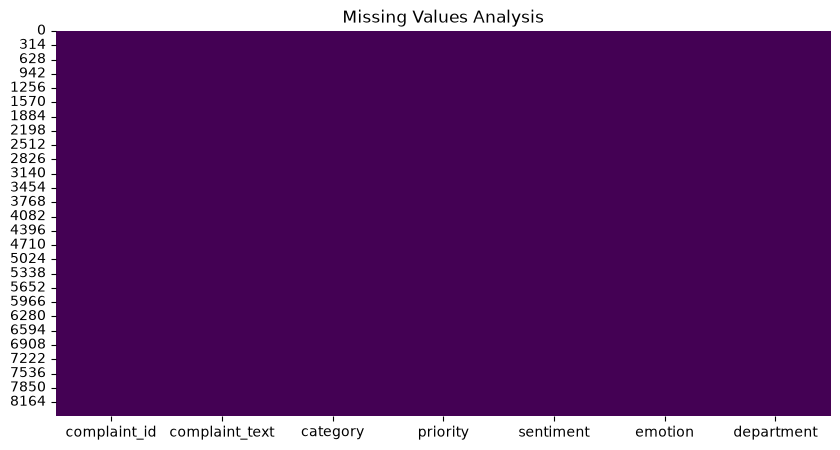

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Analysis")
plt.show()

In [25]:
expected_columns = [
    "complaint_id",
    "complaint_text",
    "category",
    "priority",
    "sentiment",
    "emotion",
    "department"
]

print("Missing columns:",
      set(expected_columns) - set(df.columns))

print("Unexpected columns:",
      set(df.columns) - set(expected_columns))

Missing columns: set()
Unexpected columns: set()


In [26]:
print(df.duplicated().sum())

0


In [27]:
print(df["complaint_id"].duplicated().sum())
print(df["complaint_text"].duplicated().sum())

0
144


In [28]:
print(df["complaint_text"].isnull().sum())

0


In [29]:
empty_text = df[
    df["complaint_text"].fillna("").str.strip() == ""
]

print("Empty complaints:", len(empty_text))

Empty complaints: 0


In [30]:
print(df.columns.nunique())

7


In [31]:
for column in expected_columns:
    
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts())

Unique values: 8469
complaint_id
1       1
2       1
3       1
4       1
5       1
       ..
8465    1
8466    1
8467    1
8468    1
8469    1
Name: count, Length: 8469, dtype: int64
Unique values: 8325
complaint_text
Product compatibility. I'm having an issue with the {product_purchased}. Please assist. I've already contacted customer support multiple times, but the issue remains unresolved.                                                                                                                                                           6
Network problem. I'm having an issue with the {product_purchased}. Please assist. I'm experiencing this issue on multiple devices of the same model, so it seems to be a widespread problem.                                                                                                                                                4
Cancellation request. I'm having an issue with the {product_purchased}. Please assist. The issue I'm facing is int

In [32]:
print(df["category"].value_counts())

category
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


In [33]:
category_percentage = (
    df["category"].value_counts(normalize=True) * 100
)

print(category_percentage.round(2))

category
Refund request          20.69
Technical issue         20.63
Cancellation request    20.01
Product inquiry         19.38
Billing inquiry         19.29
Name: proportion, dtype: float64


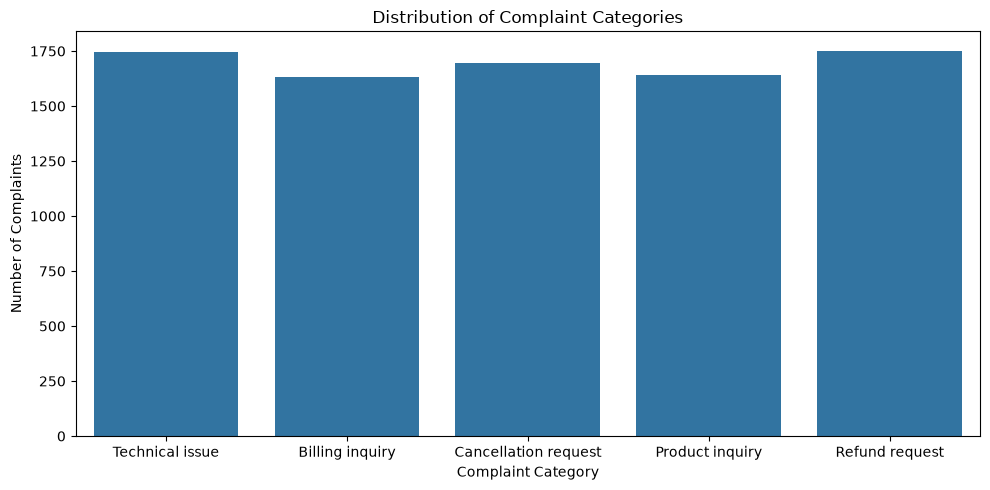

In [34]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    x=df["category"]
)
plt.title("Distribution of Complaint Categories")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

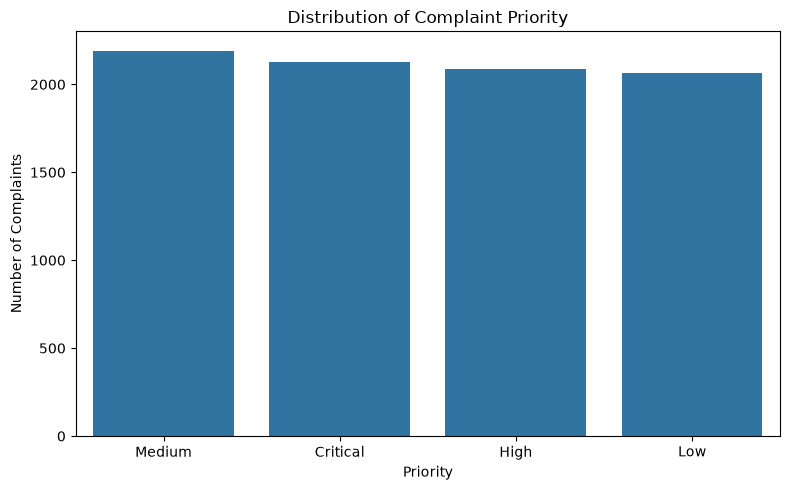

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="priority",
    order=df["priority"].value_counts().index
)

plt.title("Distribution of Complaint Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

sentiment
Positive    5892
Negative    2186
Neutral      391
Name: count, dtype: int64


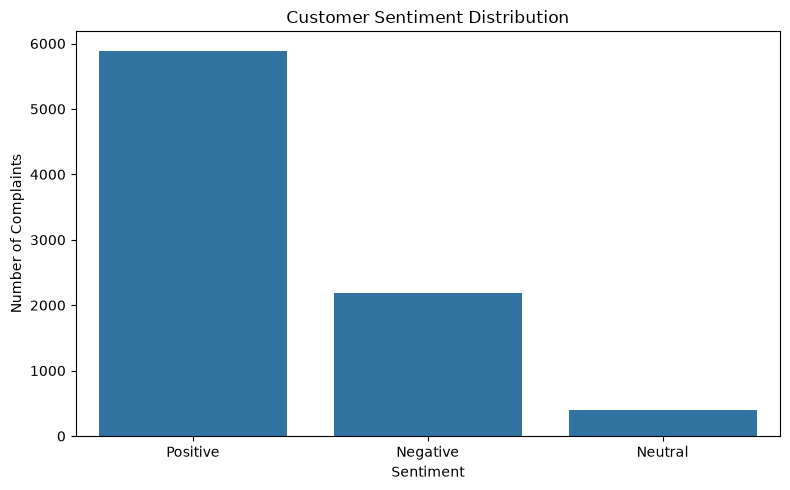

In [36]:
# %% Sentiment distribution

print(df["sentiment"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=df["sentiment"].value_counts().index
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

emotion
Other         5959
Satisfied     1192
Angry          750
Frustrated     410
Sad            158
Name: count, dtype: int64


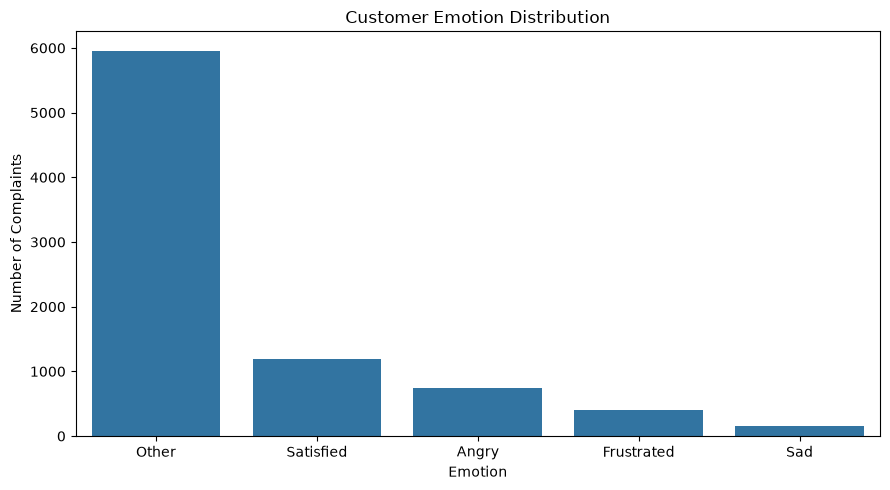

In [37]:
# %% Emotion distribution

print(df["emotion"].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="emotion",
    order=df["emotion"].value_counts().index
)

plt.title("Customer Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Complaints")

plt.tight_layout()
plt.show()

In [38]:
# %% Category vs Sentiment

category_priority = pd.crosstab(
    df["category"],
    df["priority"]
)

print(category_priority)

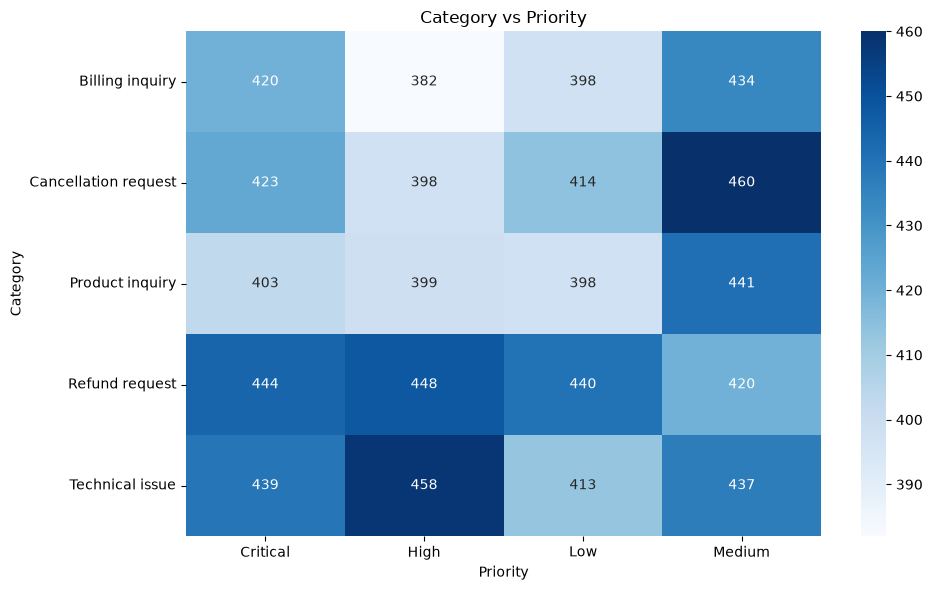

In [39]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_priority,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Category vs Priority")
plt.xlabel("Priority")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [40]:
category_priority_pct = pd.crosstab(
    df["category"],
    df["priority"],
    normalize="index"
) * 100

print(category_priority_pct.round(2))

priority              Critical   High    Low  Medium
category                                            
Billing inquiry          25.70  23.38  24.36   26.56
Cancellation request     24.96  23.48  24.42   27.14
Product inquiry          24.56  24.31  24.25   26.87
Refund request           25.34  25.57  25.11   23.97
Technical issue          25.13  26.22  23.64   25.01


In [41]:
# %% Category vs Sentiment

category_sentiment = pd.crosstab(
    df["category"],
    df["sentiment"]
)

print(category_sentiment)

sentiment             Negative  Neutral  Positive
category                                         
Billing inquiry            435       71      1128
Cancellation request       426       74      1195
Product inquiry            413       73      1155
Refund request             460       83      1209
Technical issue            452       90      1205


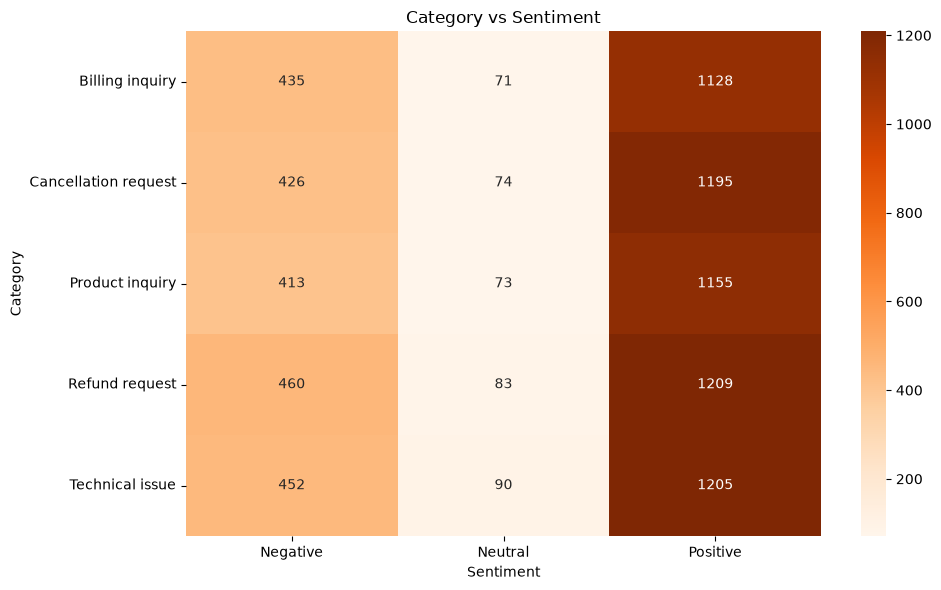

In [42]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_sentiment,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Category vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

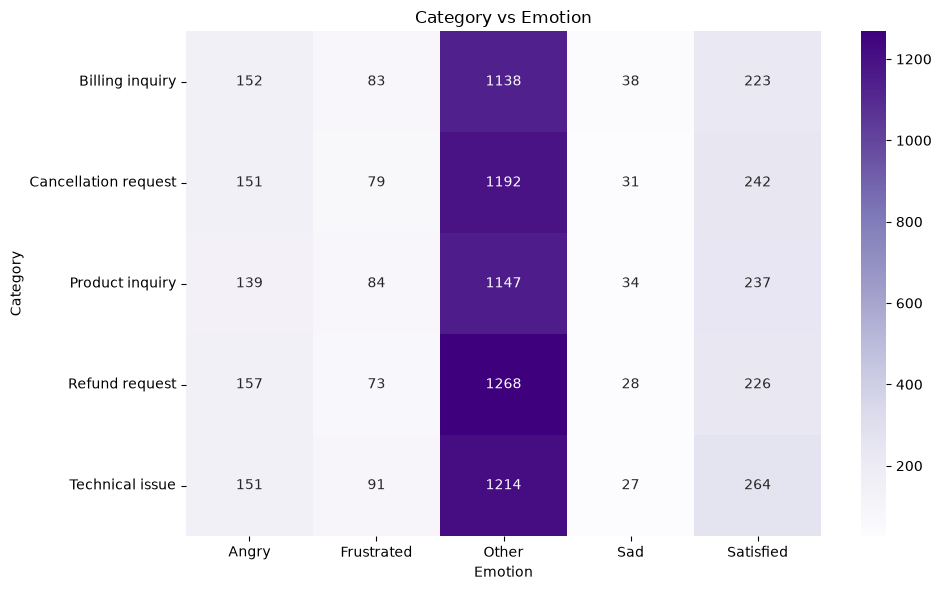

In [43]:
# %% Category vs Emotion

category_emotion = pd.crosstab(
    df["category"],
    df["emotion"]
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    category_emotion,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Category vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [44]:
# %% Text length

df["text_length"] = df["complaint_text"].fillna("").str.len()

df["word_count"] = (
    df["complaint_text"].fillna("").str.split().str.len()
)

print(df[["text_length", "word_count"]].describe())

       text_length   word_count
count  8469.000000  8469.000000
mean    307.546818    48.467352
std      43.809154     8.461730
min     162.000000    23.000000
25%     290.000000    45.000000
50%     316.000000    51.000000
75%     336.000000    54.000000
max     415.000000    65.000000


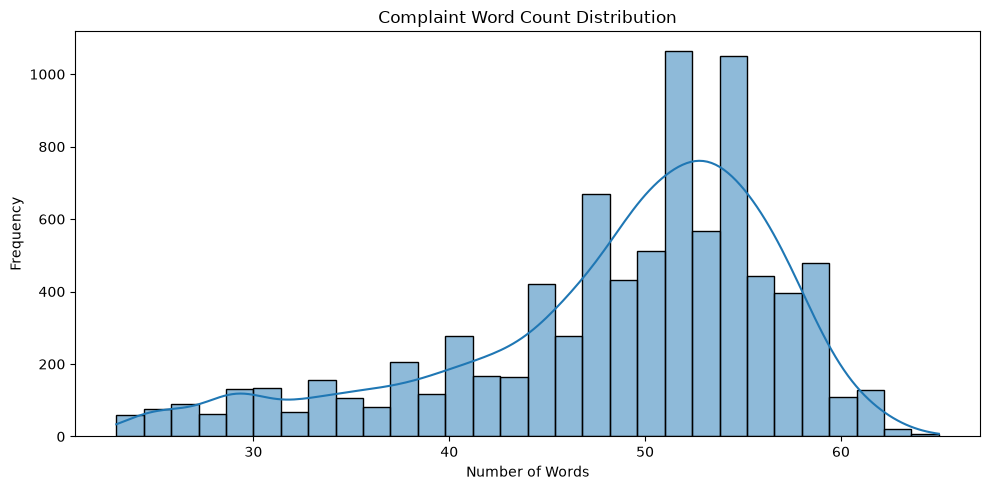

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    kde=True
)

plt.title("Complaint Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [46]:
# %% Most frequent words

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words=None,
    max_features=20
)

X = vectorizer.fit_transform(
    df["complaint_text"].fillna("")
)

word_counts = X.sum(axis=0).A1

word_frequency = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "frequency": word_counts
}).sort_values(
    by="frequency",
    ascending=False
)

print(word_frequency)

                 word  frequency
14                the      26454
13  product_purchased      14078
6               issue      13082
16                 to      10820
8                  my       9597
10             please       8815
7                  it       8747
18               with       8328
0                  an       7251
4              having       6430
2              assist       6258
17                 ve       6120
1                 and       6022
5                  is       5671
19                you       4770
3                 but       4385
15               this       4359
12            product       3946
9                  on       3941
11            problem       3385


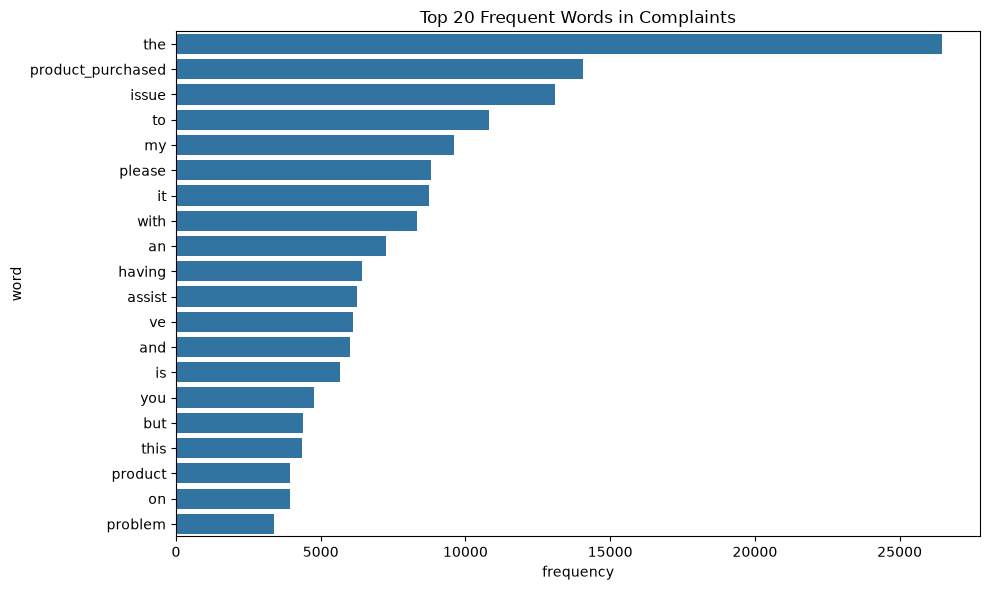

In [47]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=word_frequency,
    x="frequency",
    y="word"
)

plt.title("Top 20 Frequent Words in Complaints")
plt.tight_layout()
plt.show()

emotion    Angry  Frustrated  Other  Sad  Satisfied
sentiment                                          
Negative     297          26   1702   52        109
Neutral       32          28    302   10         19
Positive     421         356   3955   96       1064


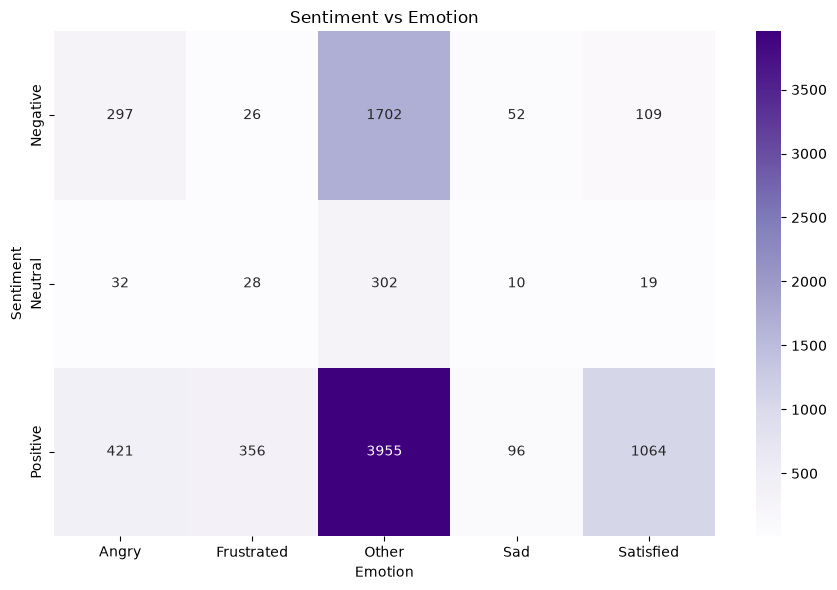

In [48]:
# %% Sentiment vs Emotion

sentiment_emotion = pd.crosstab(
    df["sentiment"],
    df["emotion"]
)

print(sentiment_emotion)

plt.figure(figsize=(9, 6))

sns.heatmap(
    sentiment_emotion,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Sentiment vs Emotion")
plt.xlabel("Emotion")
plt.ylabel("Sentiment")

plt.tight_layout()
plt.show()

In [49]:
df[["complaint_text", "text_length", "word_count", "category"]].head()

,complaint_text,text_length,word_count,category
0,Product setup. I'm having an issue with the {p...,299,45,Technical issue
1,Peripheral compatibility. I'm having an issue ...,308,46,Technical issue
2,Network problem. I'm facing a problem with my ...,292,44,Technical issue
3,Account access. I'm having an issue with the {...,278,43,Billing inquiry
4,Data loss. I'm having an issue with the {produ...,344,57,Billing inquiry


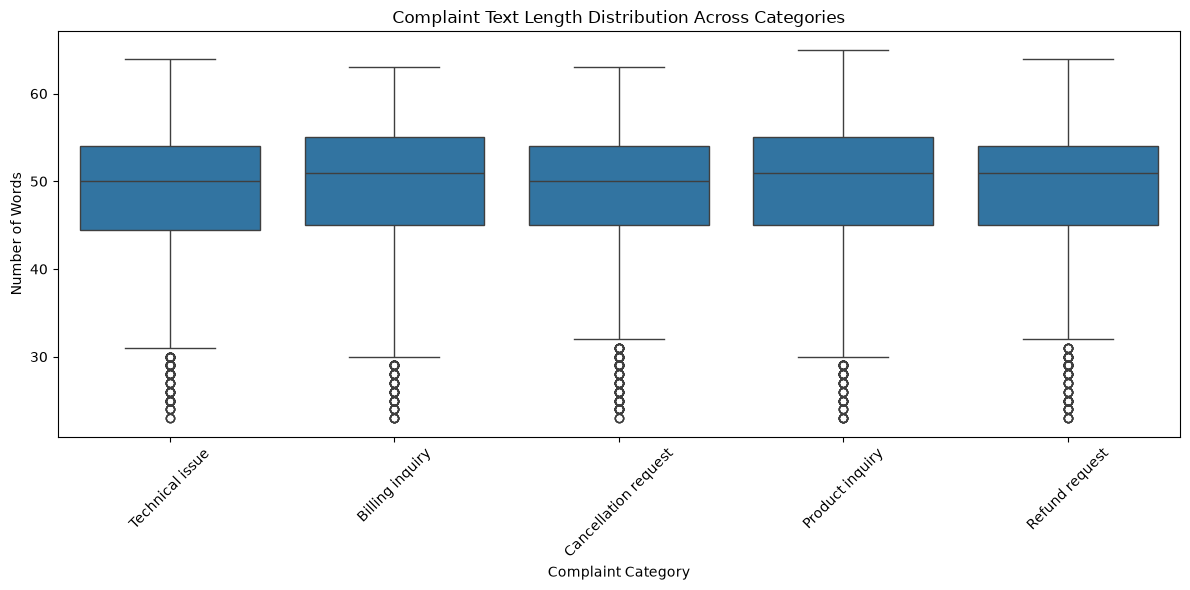

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="category",
    y="word_count"
)

plt.title("Complaint Text Length Distribution Across Categories")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Words")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [51]:
# %% EDA Summary

print("=" * 40)
print("COMPLAINT DATASET EDA SUMMARY")
print("=" * 40)

print("Total Complaints:", len(df))

print("Unique Complaint IDs:", df["complaint_id"].nunique())

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("\nCategory Distribution:")
print(df["category"].value_counts())

print("\nPriority Distribution:")
print(df["priority"].value_counts())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nEmotion Distribution:")
print(df["emotion"].value_counts())

print("\nDepartment Distribution:")
print(df["department"].value_counts())

print("=" * 40)

COMPLAINT DATASET EDA SUMMARY
Total Complaints: 8469
Unique Complaint IDs: 8469
Missing Values: 0
Duplicate Rows: 0

Category Distribution:
category
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Priority Distribution:
priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64

Sentiment Distribution:
sentiment
Positive    5892
Negative    2186
Neutral      391
Name: count, dtype: int64

Emotion Distribution:
emotion
Other         5959
Satisfied     1192
Angry          750
Frustrated     410
Sad            158
Name: count, dtype: int64

Department Distribution:
department
Billing              3386
Technical Support    1747
Retention            1695
Product              1641
Name: count, dtype: int64


In [52]:
print(df.info())
print(df.isnull().sum())
print(df["category"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   complaint_id    8469 non-null   int64
 1   complaint_text  8469 non-null   str  
 2   category        8469 non-null   str  
 3   priority        8469 non-null   str  
 4   sentiment       8469 non-null   str  
 5   emotion         8469 non-null   str  
 6   department      8469 non-null   str  
 7   text_length     8469 non-null   int64
 8   word_count      8469 non-null   int64
dtypes: int64(3), str(6)
memory usage: 595.6 KB
None
complaint_id      0
complaint_text    0
category          0
priority          0
sentiment         0
emotion           0
department        0
text_length       0
word_count        0
dtype: int64
category
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64
